In [36]:
#Importing Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully")

Libraries imported successfully


In [37]:
wine = load_wine(as_frame=True)

x = wine.data
y = wine.target

print("Dataset Shape:",x.shape)
print("Target Shape:",y.shape)


Dataset Shape: (178, 13)
Target Shape: (178,)


In [38]:
print("Feature Names:")
for feature in wine.feature_names:
     print(".",feature)
print("\nTarget Classes:")
for class_id,class_name in enumerate(wine.target_names):
    print(class_id,"=",class_name)

Feature Names:
. alcohol
. malic_acid
. ash
. alcalinity_of_ash
. magnesium
. total_phenols
. flavanoids
. nonflavanoid_phenols
. proanthocyanins
. color_intensity
. hue
. od280/od315_of_diluted_wines
. proline

Target Classes:
0 = class_0
1 = class_1
2 = class_2


In [39]:
df = wine.frame

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

In [41]:
print("Total missing values:",df.isnull().sum().sum())

Total missing values: 0


In [42]:
class_counts = y.value_counts().sort_index()

print(class_counts)

target
0    59
1    71
2    48
Name: count, dtype: int64


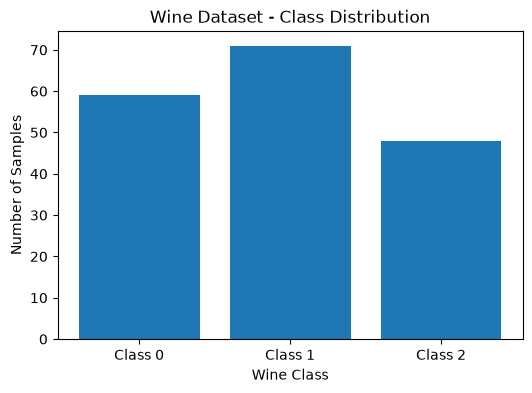

In [43]:
plt.figure(figsize=(6,4))

plt.bar(
    ['Class 0','Class 1','Class 2'],
    class_counts.values
)
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.title("Wine Dataset - Class Distribution")

plt.show()

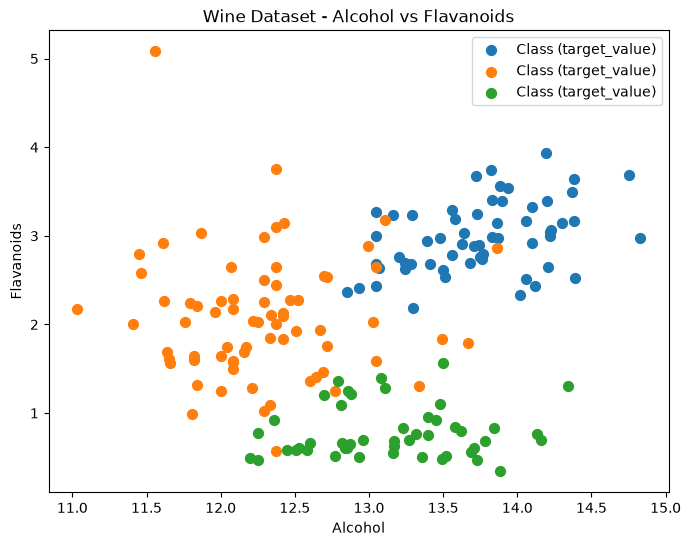

In [44]:
plt.figure(figsize=(8,6))

for target_value in [0,1,2]:

    subset = x[y == target_value]

    plt.scatter(
        subset['alcohol'],
        subset['flavanoids'],
        label=f'Class (target_value)',
        s=50
)

plt.xlabel("Alcohol")
plt.ylabel("Flavanoids")
plt.title("Wine Dataset - Alcohol vs Flavanoids")
plt.legend()
plt.show()

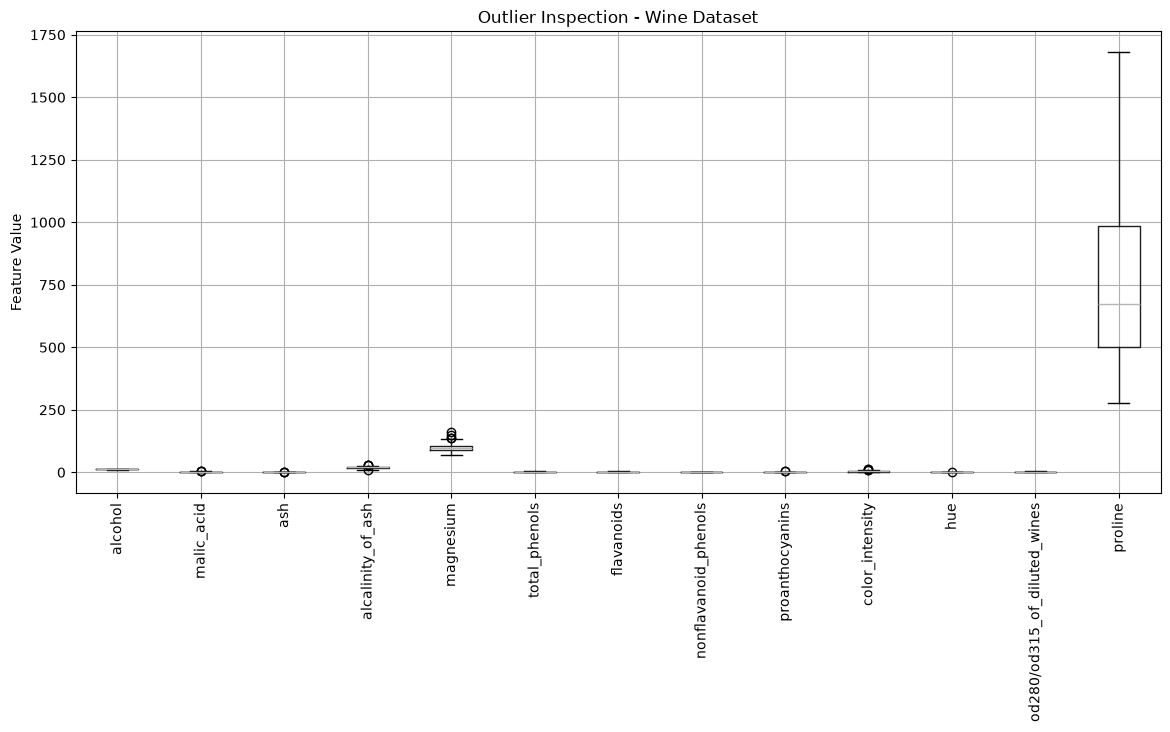

In [45]:
plt.figure(figsize=(14,6))

x.boxplot()

plt.xticks(rotation=90)
plt.title("Outlier Inspection - Wine Dataset")
plt.ylabel("Feature Value")

plt.show()

In [46]:
x = wine.data
y = wine.target

print("Number of observations:",x.shape[0])
print("Number of features    :",x.shape[1])

Number of observations: 178
Number of features    : 13


In [47]:
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:",x_train.shape)
print("Testing data:",x_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())
    

Training data: (142, 13)
Testing data: (36, 13)

Training class distribution:
target
0    47
1    57
2    38
Name: count, dtype: int64

Testing class distribution:
target
0    12
1    14
2    10
Name: count, dtype: int64


In [51]:
dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42)
dt_model.fit(x_train,y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [53]:
y_pred_dt = dt_model.predict(x_test)
print("First 10 predictions:")
print(y_pred_dt[:10])

First 10 predictions:
[0 1 0 1 1 0 0 1 1 2]
